**Писаренко Анастасия, отчет ML2**

## Задача кластеризации автомобилей

Цель - разбить автомобили на группы по характеристикам (цена, пробег, мощность и т. д.) методами обучения без учителя и сравнить три алгоритма:

- **KMeans** - разбиение на k кластеров минимизацией суммарных квадратов расстояний до центроидов;
- **DBSCAN** - плотностная кластеризация, выделяющая также шумовые точки;
- **Agglomerative Clustering** - иерархическое объединение объектов в дендрограмму.

Дополнительно проверяем устойчивость кластеров и интерпретируем полученные сегменты. Кластеризация выполняется на исходных объектах после обработки пропусков: балансировка и генерация синтетических объектов не применяются, поскольку они используют целевой класс и изменяют структуру данных. Метки `evaluation_class` служат только внешним эталоном для ARI и не участвуют ни в формировании выборки, ни в обучении моделей.

In [2]:
!pip install kagglehub

In [3]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"stlksvn","key":"b97b6ae100b37793bb70dabfe6021402"}'}

In [4]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [5]:
import kagglehub
path = kagglehub.dataset_download("chaitanyajamble/car-evaluation")
print("Path:", path)

100%|██████████| 396k/396k [00:00<00:00, 20.0MB/s]

Extracting files...
Path: /root/.cache/kagglehub/datasets/chaitanyajamble/car-evaluation/versions/1


Импорт библиотек
pandas, numpy - работа с таблицами и массивами;
matplotlib, seaborn - визуализация;
glob - поиск CSV-файлов на диске;
sklearn - препроцессинг (StandardScaler, LabelEncoder, OneHotEncoder), кластеризация (KMeans, DBSCAN, AgglomerativeClustering), метрики (silhouette_score, adjusted_rand_score, davies_bouldin_score, adjusted_mutual_info_score), PCA, NearestNeighbors;
scipy.cluster.hierarchy - дендрограмма и fcluster;
time - замер времени;
RANDOM_STATE = 42 фиксирует воспроизводимость.

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob, warnings, time
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score, davies_bouldin_score
from sklearn.metrics import adjusted_mutual_info_score
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.optimize import linear_sum_assignment
from sklearn.utils import resample

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 180)

sns.set_style("whitegrid")
RANDOM_STATE = 42

Ищем все CSV-файлы в папке датасета и читаем первый через pd.read_csv. Удаляем car_id (идентификатор, не несёт смысла), customer_review_text (текст, NLP не обрабатываем), model (слишком много уникальных значений - риск переобучения). inspection_date конвертируем в datetime, извлекаем год в inspection_year, исходный столбец удаляем. Удаляем точные дубликаты (drop_duplicates) и выводим, сколько удалено (в данном случае 0). Выводим форму и первые строки.

In [7]:
csv_files = glob.glob(path + "/*.csv")
df = pd.read_csv(csv_files[0])

df = df.drop(columns=['car_id', 'customer_review_text', 'model'])
df['inspection_date'] = pd.to_datetime(df['inspection_date'], errors='coerce')
df['inspection_year'] = df['inspection_date'].dt.year
df = df.drop(columns=['inspection_date'])

n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Удалено дубликатов: {n_before - len(df)}")

print("Форма:", df.shape)
df.head()

Удалено дубликатов: 0
Форма: (10000, 19)


,brand,manufacture_year,region,buying_price_level,price_usd,maintenance_cost_level,annual_maintenance_usd,doors,seating_capacity,luggage_boot_size,safety_rating,fuel_type,transmission,engine_size_l,horsepower,mileage_km,owner_count,evaluation_class,inspection_year
0,Maruti Suzuki,2013,North America,vhigh,35415.74,med,889.71,2,more,big,high,Petrol,Manual,2.0,114.0,151369.0,1.0,acceptable,2025
1,Kia,2007,Western Europe,high,31249.33,high,1646.84,3,4,med,low,Hybrid,Automatic,1.8,86.0,87809.0,2.0,unacceptable,2023
2,Hyundai,2020,Southeast Asia,high,35062.70,high,2290.45,5more,4,med,med,Petrol,Automatic,2.3,127.0,55745.0,4.0,unacceptable,2024
3,Chevrolet,2011,Western Europe,med,23722.04,med,974.69,4,2,med,high,Petrol,Manual,2.1,111.0,212742.0,2.0,unacceptable,2025
4,Honda,2013,Africa,low,16179.22,med,1213.57,2,4,small,med,Petrol,Manual,0.9,60.0,120923.0,4.0,unacceptable,2024


### Гистограммы и ящики с усами

Строим гистограммы распределения всех числовых признаков. Для совместного boxplot признаки дополнительно z-стандартизируем: иначе `mileage_km` и `price_usd` из-за масштаба делают остальные распределения нечитаемыми. Стандартизация здесь нужна только для визуализации. Потенциальные выбросы не удаляем автоматически, поскольку они могут соответствовать реальным автомобилям.

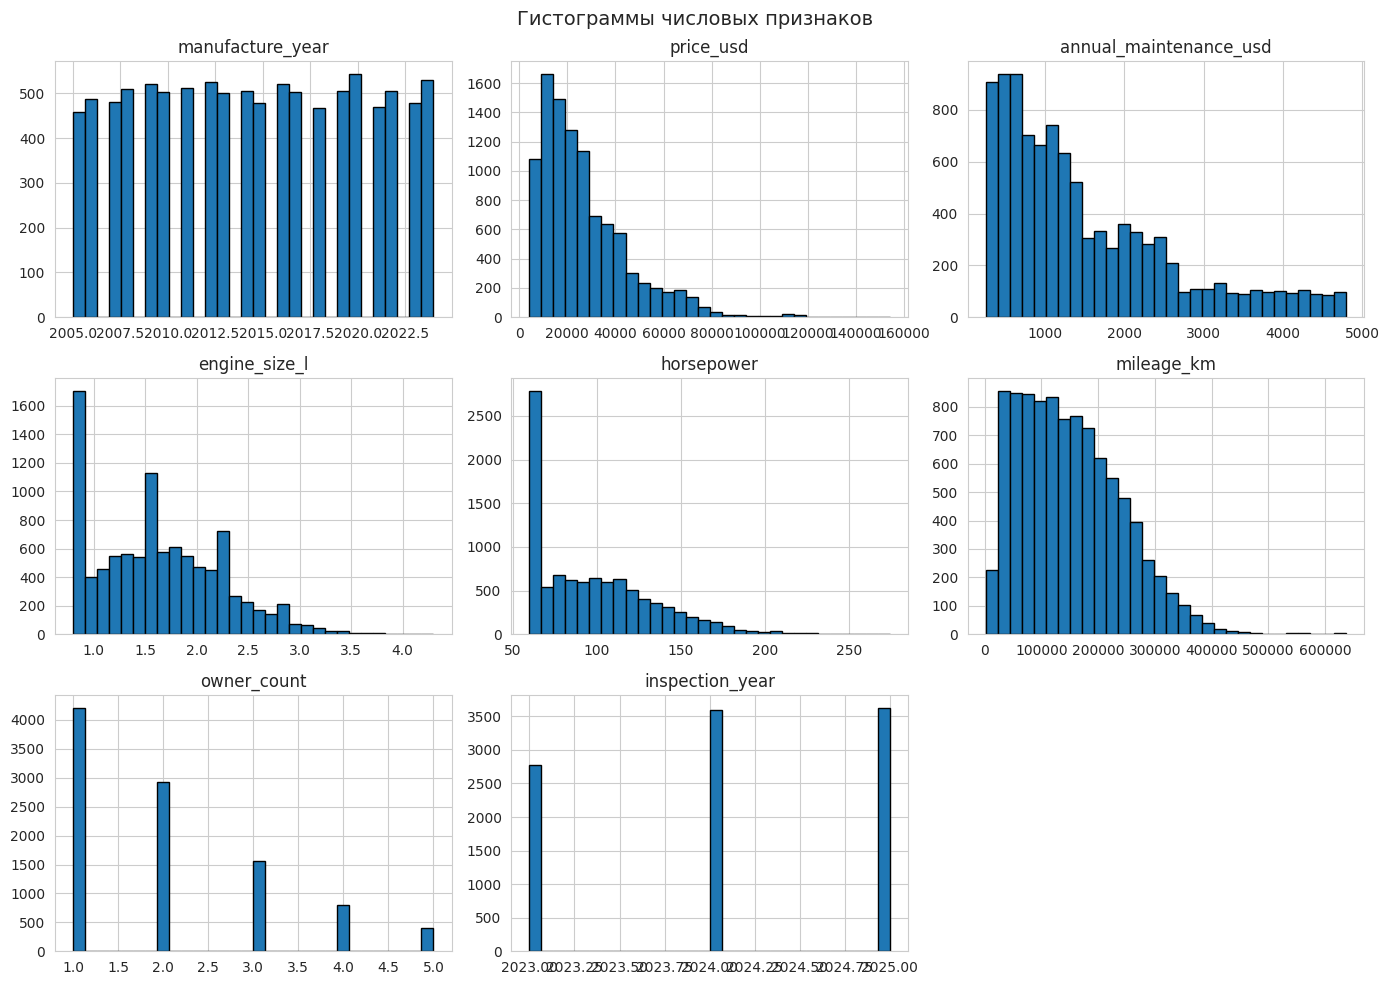

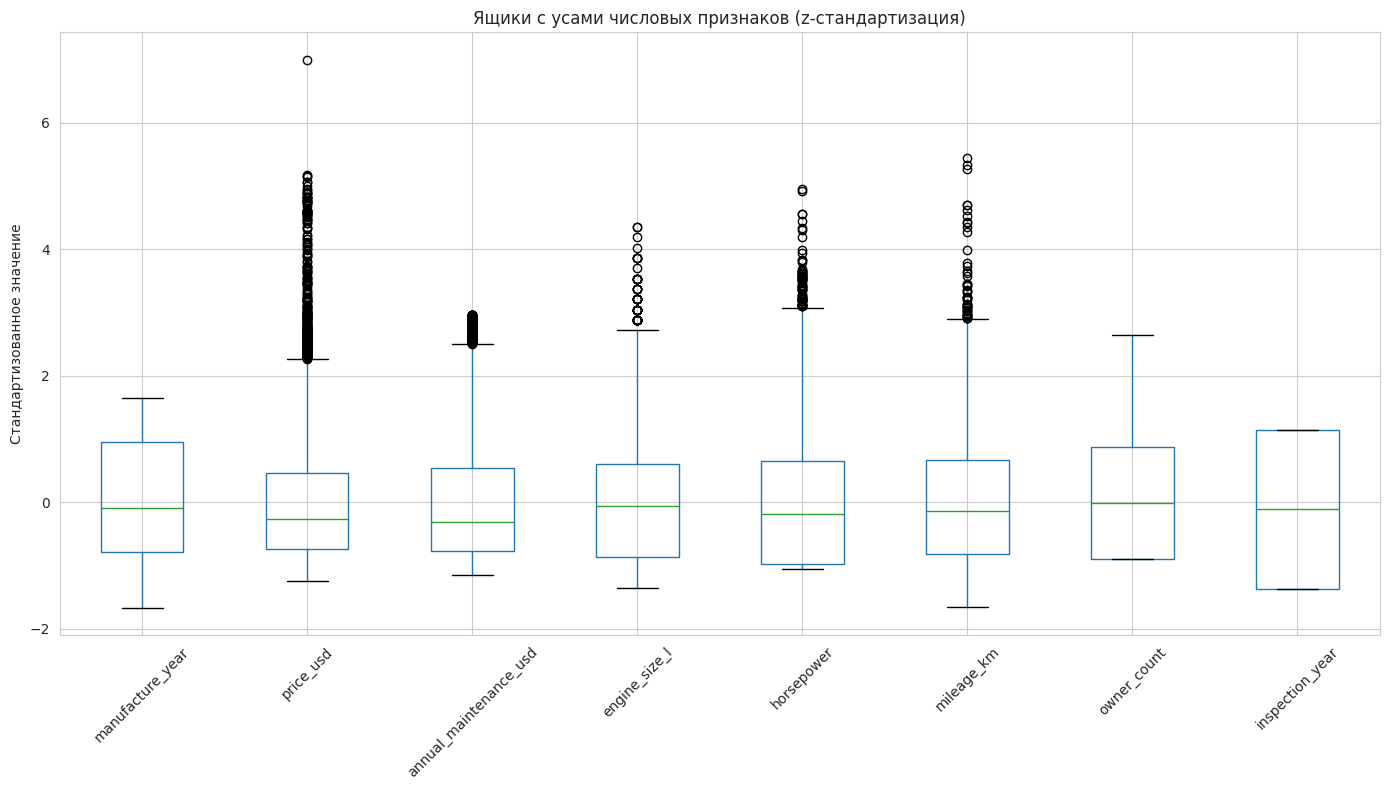

In [8]:
num_cols_preview = df.select_dtypes(include=[np.number]).columns.tolist()

df[num_cols_preview].hist(figsize=(14, 10), bins=30, edgecolor='black')
plt.suptitle('Гистограммы числовых признаков', fontsize=14)
plt.tight_layout()
plt.show()

df_scaled_preview = pd.DataFrame(
    StandardScaler().fit_transform(df[num_cols_preview]),
    columns=num_cols_preview
)
plt.figure(figsize=(14, 8))
df_scaled_preview.boxplot(rot=45)
plt.title('Ящики с усами числовых признаков (z-стандартизация)')
plt.ylabel('Стандартизованное значение')
plt.tight_layout()
plt.show()

### Диаграммы рассеяния по ключевым парам

Строим scatter-графики для трёх пар признаков: `price_usd` и `horsepower`, `mileage_km` и `manufacture_year`, `engine_size_l` и `horsepower`. Графики помогают оценить зависимости и визуально проверить наличие отдельных групп, но окончательные выводы о кластерной структуре делаем по метрикам в полном препроцессированном пространстве.

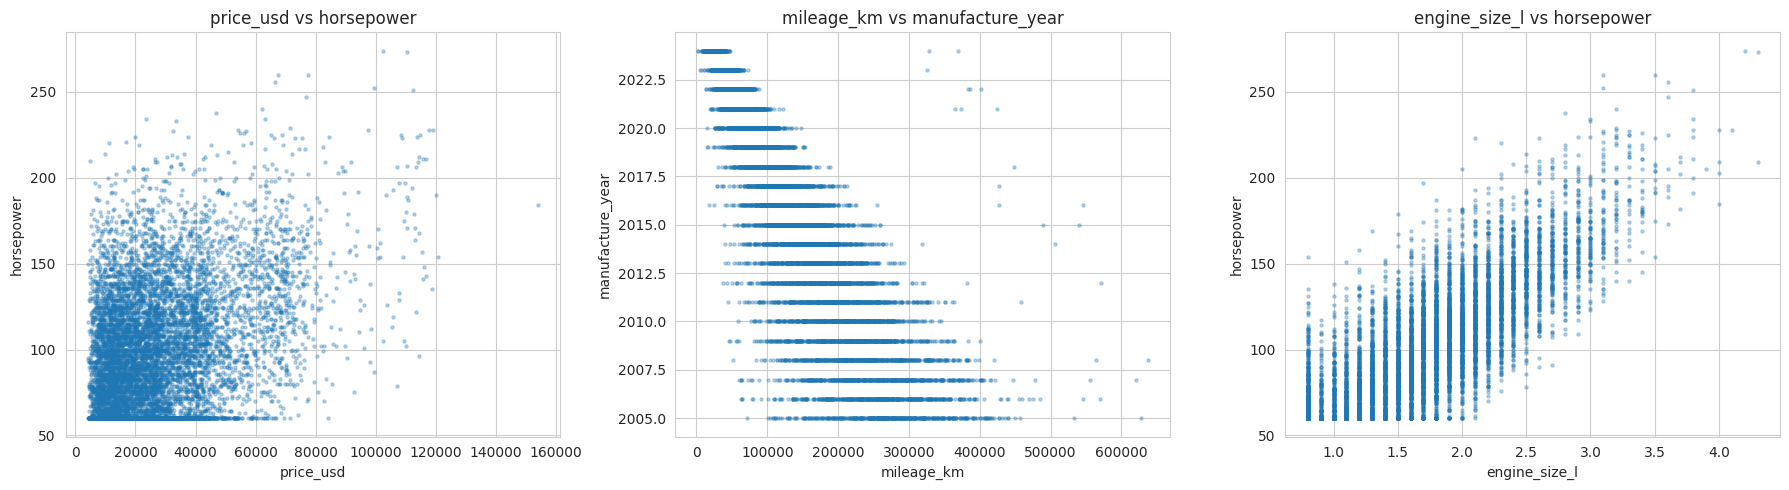

In [9]:
key_pairs = [('price_usd', 'horsepower'),
             ('mileage_km', 'manufacture_year'),
             ('engine_size_l', 'horsepower')]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (x_col, y_col) in zip(axes, key_pairs):
    if x_col in df.columns and y_col in df.columns:
        ax.scatter(df[x_col], df[y_col], alpha=0.3, s=5)
        ax.set_xlabel(x_col)
        ax.set_ylabel(y_col)
        ax.set_title(f'{x_col} vs {y_col}')
plt.tight_layout()
plt.show()

### Определение целевой переменной и X
Определяем целевую переменную evaluation_class. В этой работе она не используется для обучения - только как внешний эталон для ARI. Кодируем метки через LabelEncoder (числа 0..3), исходные текстовые метки сохраняем в y_true_labels. Формируем X - все признаки без целевой. Выводим классы и распределение: виден сильный дисбаланс (unacceptable - 70%, acceptable - 22%, good - 4.5%, very_good - 3.5%).

In [10]:
target_col = 'evaluation_class'

y_true_labels = df[target_col].copy()
le = LabelEncoder()
y_true = le.fit_transform(y_true_labels)

print("Классы:", list(le.classes_))
print(y_true_labels.value_counts())

X = df.drop(columns=[target_col])

Классы: ['acceptable', 'good', 'unacceptable', 'very_good']
evaluation_class
unacceptable    7000
acceptable      2200
good             450
very_good        350
Name: count, dtype: int64


### Анализ пропусков

Строим сводную таблицу по пропускам: количество, долю и тип данных. Выводим общее число пропусков и их долю от всех ячеек. Дополнительно строим столбчатую диаграмму доли пропусков и гистограммы для всех четырёх числовых признаков, в которых есть NA.

Столбцы с пропусками:
                        missing_count  missing_pct    dtype
mileage_km                        398         3.98  float64
horsepower                        250         2.50  float64
annual_maintenance_usd            150         1.50  float64
owner_count                       100         1.00  float64
Всего пропусков: 898 (0.473%)


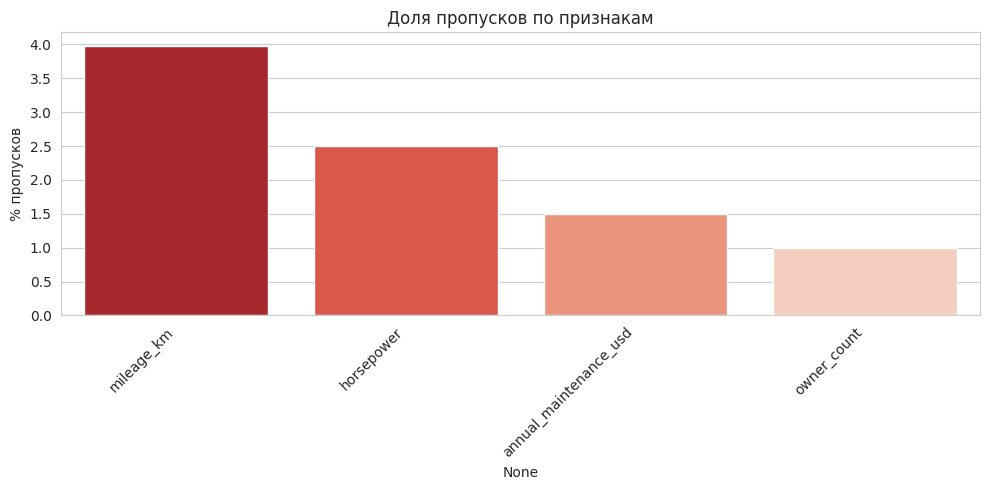

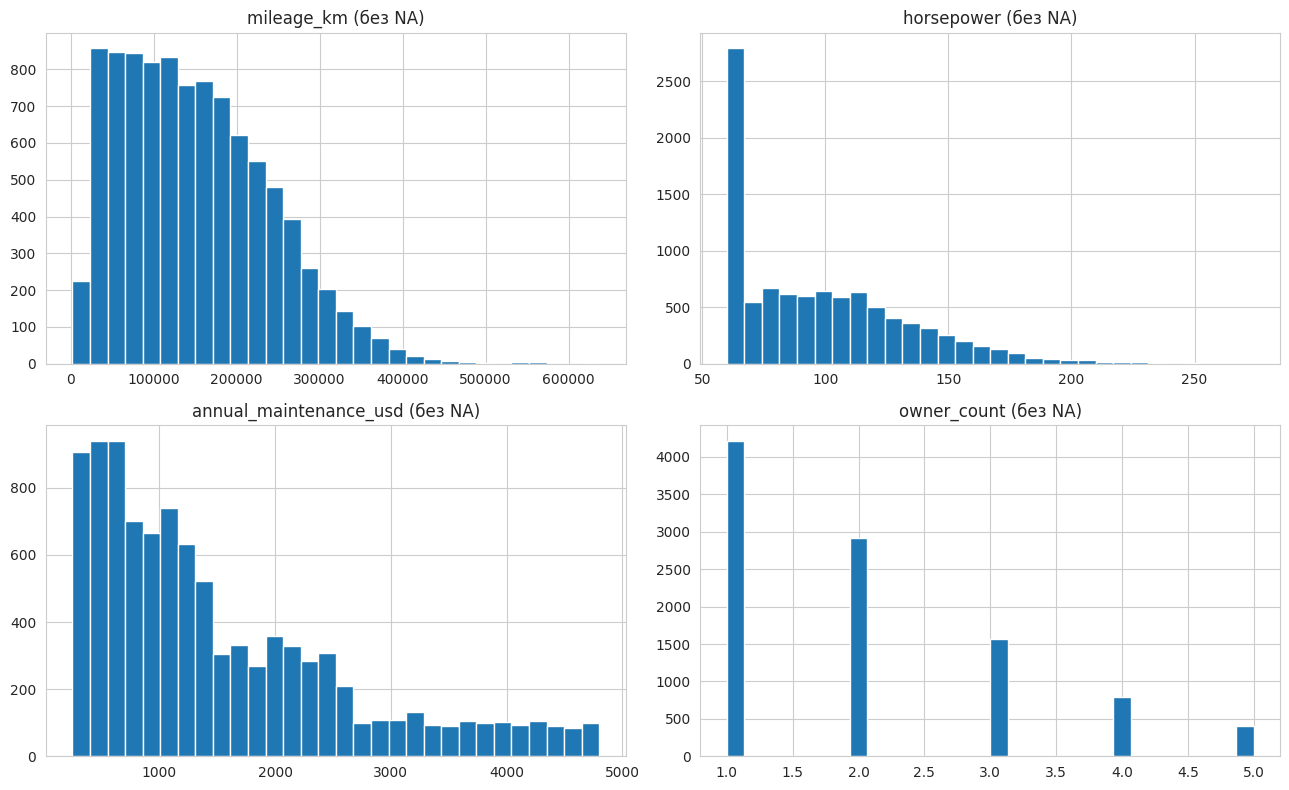

In [11]:
missing = pd.DataFrame({
    'missing_count': df.isnull().sum(),
    'missing_pct': (df.isnull().sum() / len(df) * 100).round(2),
    'dtype': df.dtypes.astype(str)
}).sort_values('missing_count', ascending=False)

print("Столбцы с пропусками:")
print(missing[missing['missing_count'] > 0])
print(f"Всего пропусков: {missing['missing_count'].sum()} "
      f"({missing['missing_count'].sum() / df.size * 100:.3f}%)")

if missing['missing_count'].sum() > 0:
    plt.figure(figsize=(10, 5))
    miss = missing[missing['missing_count'] > 0]
    sns.barplot(x=miss.index, y=miss['missing_pct'], palette='Reds_r')
    plt.ylabel('% пропусков')
    plt.title('Доля пропусков по признакам')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

cols_with_na = [
    c for c in missing[missing['missing_count'] > 0].index
    if pd.api.types.is_numeric_dtype(df[c])
]
if cols_with_na:
    ncols = 2
    nrows = int(np.ceil(len(cols_with_na) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(13, 4 * nrows))
    for ax, col in zip(np.ravel(axes), cols_with_na):
        df[col].dropna().hist(ax=ax, bins=30)
        ax.set_title(f'{col} (без NA)')
    for ax in np.ravel(axes)[len(cols_with_na):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

### Обработка пропусков по порогу
Если доля пропусков в столбце >= 5%, удаляем строки с пропусками; иначе заполняем числовые медианой, категориальные - модой. В текущем датасете порог 5% не превышен ни в одном столбце - все пропуски заполнены, ни одна строка не удалена. После обновления df заново собираем списки num_cols и cat_cols, исключая целевую переменную.

In [12]:
THRESHOLD_PCT = 5.0
df_clean = df.copy()

num_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df_clean.select_dtypes(include=['object']).columns.tolist()

dropped_rows = 0
for col in df_clean.columns:
    if df_clean[col].isnull().sum() == 0:
        continue
    pct = df_clean[col].isnull().mean() * 100
    if pct >= THRESHOLD_PCT:
        n_before = len(df_clean)
        df_clean = df_clean.dropna(subset=[col]).reset_index(drop=True)
        dropped_rows += n_before - len(df_clean)
        print(f"[DROP] {col}: удалено {n_before - len(df_clean)} строк ({pct:.1f}%)")
    else:
        if pd.api.types.is_numeric_dtype(df_clean[col]):
            fill_value = df_clean[col].median()
            df_clean[col] = df_clean[col].fillna(fill_value)
            print(f"[FILL] {col}: медиана = {fill_value:.3f}")
        else:
            fill_value = df_clean[col].mode()[0]
            df_clean[col] = df_clean[col].fillna(fill_value)
            print(f"[FILL] {col}: мода = {fill_value}")

print(f"Всего удалено строк: {dropped_rows}")
print(f"Всего пропусков после: {df_clean.isnull().sum().sum()}")
print("Форма:", df_clean.shape)

df = df_clean
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
num_cols = [c for c in num_cols if c != target_col]
cat_cols = [c for c in cat_cols if c != target_col]

print("Числовые:", num_cols)
print("Категориальные:", cat_cols)

[FILL] annual_maintenance_usd: медиана = 1167.990
[FILL] horsepower: медиана = 91.000
[FILL] mileage_km: медиана = 138639.500
[FILL] owner_count: медиана = 2.000
Всего удалено строк: 0
Всего пропусков после: 0
Форма: (10000, 19)
Числовые: ['manufacture_year', 'price_usd', 'annual_maintenance_usd', 'engine_size_l', 'horsepower', 'mileage_km', 'owner_count', 'inspection_year']
Категориальные: ['brand', 'region', 'buying_price_level', 'maintenance_cost_level', 'doors', 'seating_capacity', 'luggage_boot_size', 'safety_rating', 'fuel_type', 'transmission']


### Формирование выборки без использования целевого класса

Для обучения без учителя сохраняем все 10 000 исходных объектов. SMOTE и undersampling здесь не применяются: они использовали бы `evaluation_class`, изменяли бы распределение признаков и делали бы последующий ARI несопоставимым с оценкой на исходных данных. Если вычислительные ограничения требуют подвыборки, её следует формировать случайно и независимо от классов; в данной работе полный датасет обрабатывается без такого сокращения.

In [13]:
X = df.drop(columns=[target_col]).reset_index(drop=True)
y_true_labels = df[target_col].reset_index(drop=True)

le = LabelEncoder()
y_true = le.fit_transform(y_true_labels)

print("Распределение классов (только для внешней оценки):")
print(y_true_labels.value_counts())
print("Форма X:", X.shape)
print("Число исходных объектов:", len(X))

Распределение классов (только для внешней оценки):
evaluation_class
unacceptable    7000
acceptable      2200
good             450
very_good        350
Name: count, dtype: int64
Форма X: (10000, 18)
Число исходных объектов: 10000


### Препроцессинг

Создаём `ColumnTransformer`: числовые признаки масштабируем через `StandardScaler`, категориальные кодируем через `OneHotEncoder(handle_unknown='ignore')`. Это необходимо потому, что KMeans, DBSCAN, иерархическая кластеризация и PCA чувствительны к масштабу и метрике расстояния. Преобразование обучается только на матрице признаков `X`, без использования `evaluation_class`.

In [14]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
    ])

X_processed = preprocessor.fit_transform(X)
X_processed = X_processed.toarray() if hasattr(X_processed, 'toarray') else X_processed
X_processed = np.asarray(X_processed)

print("Форма после препроцессинга:", X_processed.shape)

Форма после препроцессинга: (10000, 59)


### Матрица корреляций числовых признаков

Строим тепловую карту корреляций с маской верхнего треугольника и выводим топ-10 пар по абсолютному коэффициенту корреляции. Корреляционный анализ помогает выявить дублирование информации, но умеренная мультиколлинеарность сама по себе не требует удаления признаков.

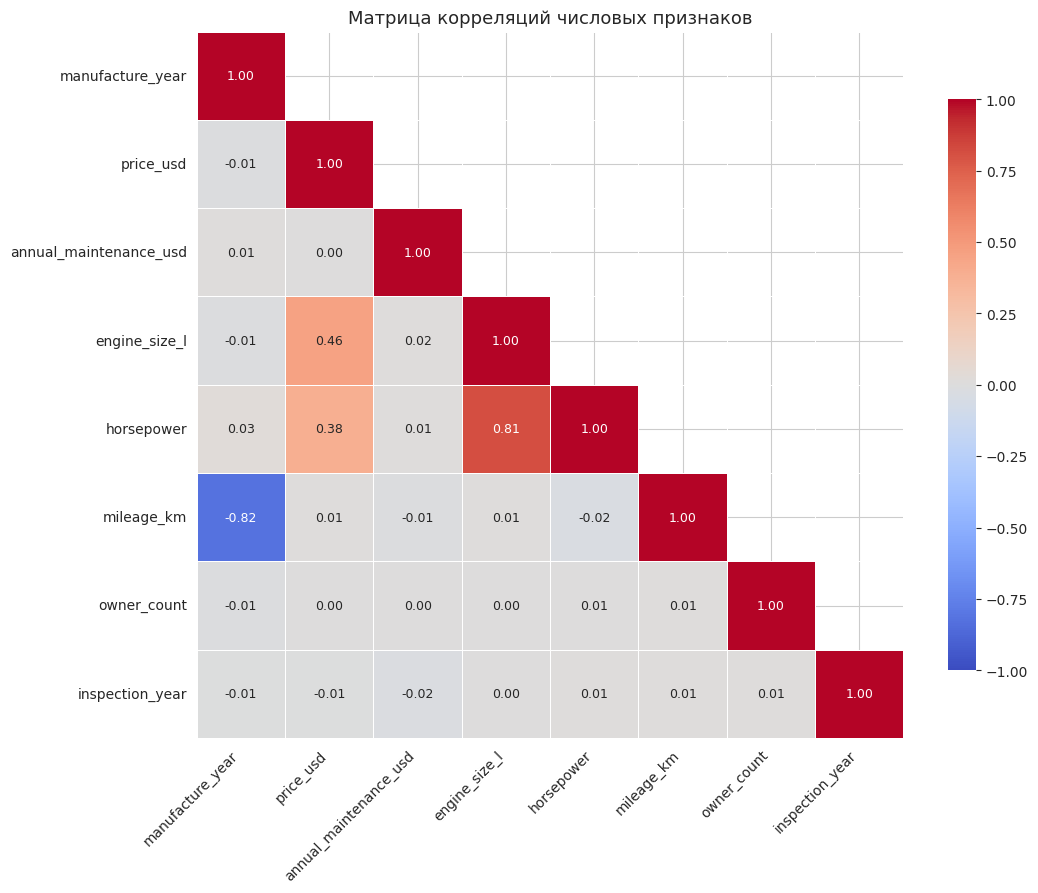

Топ-10 коррелированных пар признаков:
mileage_km              manufacture_year          0.822
horsepower              engine_size_l             0.815
engine_size_l           price_usd                 0.457
horsepower              price_usd                 0.384
                        manufacture_year          0.027
mileage_km              horsepower                0.024
inspection_year         annual_maintenance_usd    0.017
engine_size_l           annual_maintenance_usd    0.015
annual_maintenance_usd  manufacture_year          0.014
mileage_km              annual_maintenance_usd    0.013
dtype: float64


In [15]:
corr_df = X[num_cols].copy()
corr_df = corr_df.loc[:, corr_df.nunique() > 1]
corr_matrix = corr_df.corr()

mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

plt.figure(figsize=(11, 9))
sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True, fmt='.2f',
    cmap='coolwarm', center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.5,
    cbar_kws={'shrink': 0.8},
    annot_kws={'size': 9}
)
plt.title('Матрица корреляций числовых признаков', fontsize=13)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

corr_pairs = (corr_matrix.abs()
              .where(~mask)
              .stack()
              .sort_values(ascending=False))
corr_pairs = corr_pairs[corr_pairs < 1.0].drop_duplicates()
print("Топ-10 коррелированных пар признаков:")
print(corr_pairs.head(10).round(3))

### Метод локтя для KMeans

Строим кривую WCSS (inertia) при k от 2 до 14 и оцениваем точку локтя по максимальному расстоянию до хорды, соединяющей крайние точки нормированной кривой. Метод локтя является эвристикой, поэтому окончательный выбор k дополнительно проверяем силуэтным анализом.

Замечание о результате: локоть указывает на k=6, но это лишь ориентир.
Решающий критерий — силуэт (максимум при k=2, след. ячейка).
Разбиение при k=2 также устойчивее (ARI≈0.975 на подвыборках) и проще
интерпретируется, поэтому итоговым выбрано k=2.

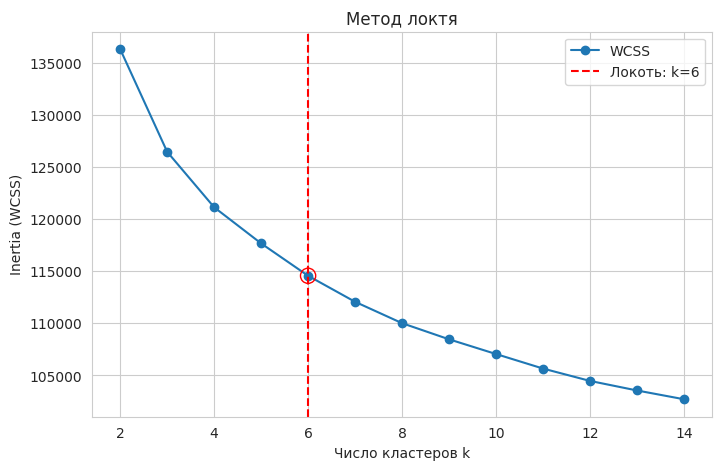

Автоматически найденная точка локтя: k = 6


In [16]:
inertias = []
K_range = range(2, 15)
for k in K_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10,
                random_state=RANDOM_STATE)
    km.fit(X_processed)
    inertias.append(km.inertia_)

ks = np.array(list(K_range), dtype=float)
wcss = np.array(inertias, dtype=float)
# Нормируем оси, чтобы расстояние до хорды не зависело от единиц измерения.
x_norm = (ks - ks.min()) / (ks.max() - ks.min())
y_norm = (wcss - wcss.min()) / (wcss.max() - wcss.min())
p1 = np.array([x_norm[0], y_norm[0]])
p2 = np.array([x_norm[-1], y_norm[-1]])
points = np.column_stack([x_norm, y_norm])
d = np.abs(np.cross(p2 - p1, p1 - points)) / np.linalg.norm(p2 - p1)
elbow_idx = int(np.argmax(d))
elbow_k = int(ks[elbow_idx])
elbow_wcss = wcss[elbow_idx]

plt.figure(figsize=(8, 5))
plt.plot(ks, wcss, marker='o', label='WCSS')
plt.axvline(elbow_k, color='r', linestyle='--',
            label=f'Локоть: k={elbow_k}')
plt.scatter([elbow_k], [elbow_wcss], s=120, facecolors='none',
            edgecolors='r', zorder=5)
plt.xlabel('Число кластеров k')
plt.ylabel('Inertia (WCSS)')
plt.title('Метод локтя')
plt.legend()
plt.grid(True)
plt.show()

print(f"Автоматически найденная точка локтя: k = {elbow_k}")

### Силуэтный анализ для KMeans

Считаем silhouette score для k от 2 до 14 и выбираем k с максимальным значением. Дополнительно учитываем, что высокий silhouette сам по себе не гарантирует содержательное разбиение: далее проверяем размеры, устойчивость и интерпретируемость кластеров.

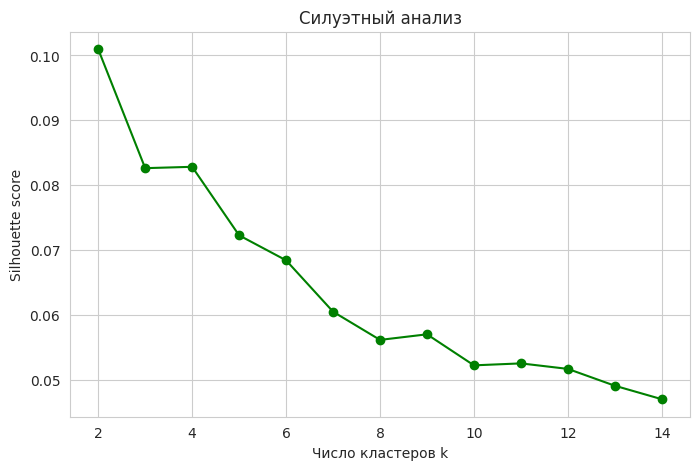

Оптимальное k по силуэту: 2 silhouette = 0.101


In [17]:
sil_scores = []
for k in K_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_processed)
    sil_scores.append(silhouette_score(X_processed, labels))

plt.figure(figsize=(8,5))
plt.plot(list(K_range), sil_scores, marker='o', color='green')
plt.xlabel('Число кластеров k')
plt.ylabel('Silhouette score')
plt.title('Силуэтный анализ')
plt.grid(True)
plt.show()

best_k = int(list(K_range)[int(np.argmax(sil_scores))])
print("Оптимальное k по силуэту:", best_k, "silhouette =", round(max(sil_scores), 4))

### Сравнение инициализаций KMeans

Сравниваем `k-means++` и `random` при `n_init=1` и `n_init=10` по inertia и silhouette. Несколько инициализаций снижают риск выбора неудачного локального минимума; итоговый вывод делаем по фактическим значениям в таблице.

In [18]:
results_init = []
for init in ['k-means++', 'random']:
    for n_init in [1, 10]:
        km = KMeans(n_clusters=best_k, init=init, n_init=n_init, random_state=RANDOM_STATE)
        labels = km.fit_predict(X_processed)
        results_init.append({
            'init': init,
            'n_init': n_init,
            'inertia': km.inertia_,
            'silhouette': silhouette_score(X_processed, labels)
        })

pd.DataFrame(results_init)

,init,n_init,inertia,silhouette
0,k-means++,1,136310.739814,0.100756
1,k-means++,10,136310.411923,0.100950
2,random,1,136310.742319,0.100788
3,random,10,136310.359083,0.100748


### Ансамбль KMeans с согласованием меток

Запускаем KMeans 30 раз со случайной инициализацией. Поскольку номера кластеров произвольны, перед объединением согласуем метки каждого запуска с базовым KMeans через задачу назначения (`linear_sum_assignment`). Итоговая метка объекта - мода согласованных меток. Такой ансамбль не требует квадратичной по числу объектов матрицы co-association и применим ко всем 10 000 объектам. Сравниваем silhouette ансамбля и одиночного KMeans, а также ARI между ними.

In [19]:
n_runs = 30
km_single = KMeans(n_clusters=best_k, init='k-means++', n_init=10,
                   random_state=RANDOM_STATE)
single_labels = km_single.fit_predict(X_processed)
aligned_runs = []

for i in range(n_runs):
    km = KMeans(n_clusters=best_k, init='random', n_init=1,
                random_state=i)
    labels = km.fit_predict(X_processed)

    contingency = np.zeros((best_k, best_k), dtype=int)
    for ref_label in range(best_k):
        for current_label in range(best_k):
            contingency[ref_label, current_label] = np.sum(
                (single_labels == ref_label) & (labels == current_label)
            )

    ref_ind, current_ind = linear_sum_assignment(-contingency)
    mapping = {current: ref for ref, current in zip(ref_ind, current_ind)}
    aligned_runs.append(np.array([mapping[x] for x in labels]))

aligned_runs = np.stack(aligned_runs, axis=0)
ensemble_labels = np.apply_along_axis(
    lambda x: np.bincount(x, minlength=best_k).argmax(),
    axis=0, arr=aligned_runs
)

print("Silhouette ансамбля:", silhouette_score(X_processed, ensemble_labels))
print("Silhouette одиночного:", silhouette_score(X_processed, single_labels))
print("ARI между ансамблем и одиночным:", adjusted_rand_score(single_labels, ensemble_labels))

Silhouette ансамбля: 0.10076998753925344
Silhouette одиночного: 0.10095044083937586
ARI между ансамблем и одиночным: 0.9915595882102198


### k-расстояния для подбора eps (DBSCAN)

Для каждой точки считаем расстояние до k-го соседа (при k=5 используем `distances[:, 5]`, поскольку нулевой сосед - сам объект). Сортировка и оценка точки перегиба дают ориентир для сетки `eps`, но окончательные параметры выбираем по совокупности silhouette, числа кластеров и доли шума.

Замечание о результате: оценка по колену ≈4.53 — только ориентир
для сетки grid search. Фактические параметры (eps=3.5, min_samples=3)
выбраны в следующей ячейке по максимуму silhouette при ограничении
noise_pct < 30%, чтобы не потерять покрытие данных.

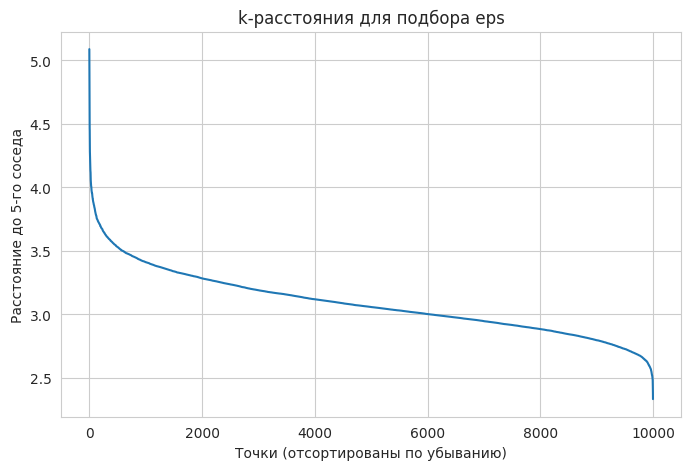

Оценка eps по колену: 4.531


In [20]:
k = 5
nbrs = NearestNeighbors(n_neighbors=k+1).fit(X_processed)
distances, _ = nbrs.kneighbors(X_processed)
k_dist = np.sort(distances[:, k])[::-1]

plt.figure(figsize=(8,5))
plt.plot(k_dist)
plt.xlabel('Точки (отсортированы по убыванию)')
plt.ylabel(f'Расстояние до {k}-го соседа')
plt.title('k-расстояния для подбора eps')
plt.grid(True)
plt.show()

dk = np.diff(k_dist)
knee_idx = int(np.argmax(np.diff(dk))) + 1
eps_estimate = float(k_dist[knee_idx])
print(f"Оценка eps по колену: {eps_estimate:.3f}")

### Grid search DBSCAN

Перебираем 72 комбинации `eps` и `min_samples`. Для каждой фиксируем число кластеров, число и долю шумовых точек, а также silhouette только на нешумовых точках. Silhouette считается лишь при наличии минимум двух кластеров и шуме менее 60%. Такой silhouette описывает качество найденных плотных групп, но не сравним напрямую с silhouette моделей, размечающих все объекты.

Про выбросы: метки −1 — это шумовые точки DBSCAN, то есть выбросы,
не попавшие ни в один плотностной кластер. Их доля — прямая оценка
доли выбросов; в стресс-тесте ниже она растёт с добавлением шума.
Поскольку silhouette считается только на нешумовых точках, его нельзя
напрямую сравнивать с KMeans/Ward, которые размечают 100% объектов.

In [21]:
results_dbscan = []
eps_grid = [0.5, 0.8, 1.0, 1.2, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 5.0, 6.0]
min_samples_grid = [3, 5, 10, 15, 20, 30]

for eps in eps_grid:
    for ms in min_samples_grid:
        db = DBSCAN(eps=eps, min_samples=ms, n_jobs=-1)
        labels = db.fit_predict(X_processed)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = int(np.sum(labels == -1))
        noise_pct = n_noise / len(labels) * 100
        if n_clusters >= 2 and noise_pct < 60:
            mask = labels != -1
            sil = silhouette_score(X_processed[mask], labels[mask])
        else:
            sil = np.nan
        results_dbscan.append({
            'eps': eps, 'min_samples': ms,
            'n_clusters': n_clusters,
            'n_noise': n_noise, 'noise_pct': round(noise_pct, 1),
            'silhouette': sil
        })

dbscan_df = (pd.DataFrame(results_dbscan)
             .sort_values('silhouette', ascending=False)
             .reset_index(drop=True))
print(dbscan_df.head(15))

    eps  min_samples  n_clusters  n_noise  noise_pct  silhouette
0   3.5            3           2      102        1.0    0.270161
1   3.0           10           5     4805       48.0   -0.042013
2   3.0            5          18     2981       29.8   -0.095365
3   3.0            3          48     2078       20.8   -0.159764
4   0.5            3           0    10000      100.0         NaN
5   0.5            5           0    10000      100.0         NaN
6   0.5           10           0    10000      100.0         NaN
7   0.5           15           0    10000      100.0         NaN
8   0.5           20           0    10000      100.0         NaN
9   0.5           30           0    10000      100.0         NaN
10  0.8            3           0    10000      100.0         NaN
11  0.8            5           0    10000      100.0         NaN
12  0.8           10           0    10000      100.0         NaN
13  0.8           15           0    10000      100.0         NaN
14  0.8           20     

### Тепловая карта числа кластеров DBSCAN

Строим heatmap зависимости числа кластеров от `eps` и `min_samples`. Карта помогает увидеть области с устойчивым числом кластеров и режимы, в которых алгоритм относит почти все объекты к шуму либо образует множество мелких групп.

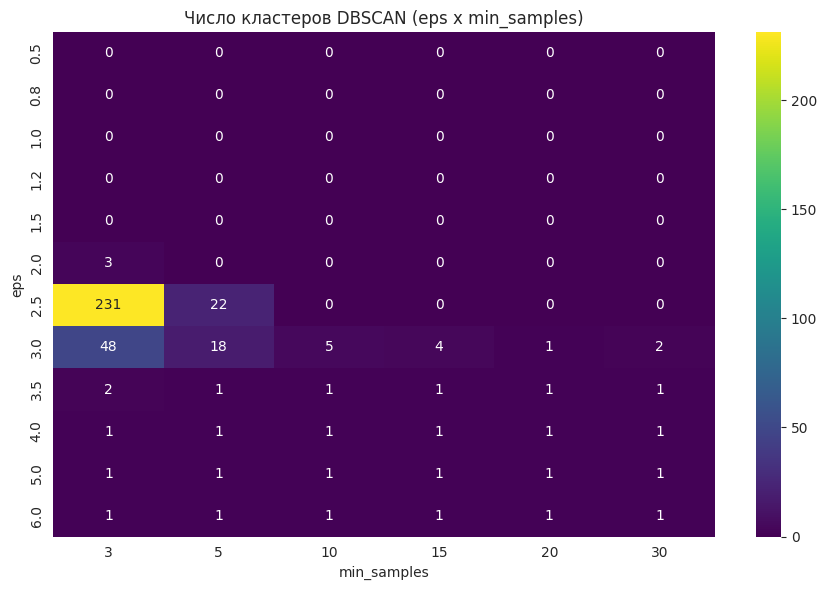

In [22]:
pivot = dbscan_df.pivot_table(
    index='eps', columns='min_samples',
    values='n_clusters', aggfunc='first')
plt.figure(figsize=(9, 6))
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='viridis')
plt.title('Число кластеров DBSCAN (eps x min_samples)')
plt.tight_layout()
plt.show()

### Выбор лучших параметров DBSCAN

Отбрасываем варианты с долей шума не менее 30%, среди оставшихся выбираем максимальный silhouette. Таким образом учитываются и качество разбиения нешумовых точек, и покрытие данных. Выбранные параметры применяем ко всем объектам.

In [23]:
valid = dbscan_df.dropna(subset=['silhouette'])
valid = valid[valid['noise_pct'] < 30]
if len(valid) > 0:
    best_eps = float(valid.iloc[0]['eps'])
    best_min_samples = int(valid.iloc[0]['min_samples'])
else:
    best_eps = float(dbscan_df.iloc[0]['eps'])
    best_min_samples = int(dbscan_df.iloc[0]['min_samples'])

print(f"Лучшие параметры DBSCAN: eps={best_eps}, min_samples={best_min_samples}")

db_final = DBSCAN(eps=best_eps, min_samples=best_min_samples, n_jobs=-1)
db_labels = db_final.fit_predict(X_processed)

n_clusters_db = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise_db = int(np.sum(db_labels == -1))
print(f"Итог: {n_clusters_db} кластеров, {n_noise_db} шумовых точек "
      f"({n_noise_db/len(db_labels)*100:.1f}%)")

Лучшие параметры DBSCAN: eps=3.5, min_samples=3
Итог: 2 кластеров, 102 шумовых точек (1.0%)


### Устойчивость DBSCAN к возмущениям

Добавляем гауссов шум разной интенсивности в препроцессированном пространстве, повторно запускаем DBSCAN и сравниваем разметку с базовой через ARI. Это стресс-тест численного представления данных: одновременно отслеживаем изменение ARI, числа кластеров и доли шума.

In [24]:
np.random.seed(RANDOM_STATE)
noise_levels = [0.0, 0.05, 0.1, 0.2, 0.3, 0.5]

print(f"{'Noise':>8} | {'Clusters':>8} | {'Noise pts':>10} | {'ARI':>6}")
print("-" * 45)
base_labels = DBSCAN(eps=best_eps, min_samples=best_min_samples).fit_predict(X_processed)
for noise in noise_levels:
    X_noisy = X_processed + np.random.normal(0, noise, X_processed.shape)
    lbl = DBSCAN(eps=best_eps, min_samples=best_min_samples).fit_predict(X_noisy)
    n_cl = len(set(lbl)) - (1 if -1 in lbl else 0)
    n_ns = int(np.sum(lbl == -1))
    ari = adjusted_rand_score(base_labels, lbl) if n_cl >= 2 else 0.0
    print(f"{noise:>8.2f} | {n_cl:>8} | {n_ns:>10} | {ari:>6.3f}")

   Noise | Clusters |  Noise pts |    ARI
---------------------------------------------
    0.00 |        2 |        102 |  1.000
    0.05 |        2 |        124 |  0.858
    0.10 |        3 |        230 |  0.545
    0.20 |       40 |       2303 |  0.043
    0.30 |      113 |       9475 | -0.017
    0.50 |        0 |      10000 |  0.000


### Сравнение методов иерархической кластеризации

Сравниваем метрики расстояния (`euclidean`, `manhattan`, `cosine`) и методы связи (`ward`, `complete`, `average`, `single`). Ward используется только с евклидовым расстоянием. Помимо silhouette и времени, выводим размер наименьшего кластера: высокий silhouette у вырожденного разбиения не означает содержательную кластеризацию.

Максимальный silhouette даёт `single + manhattan` (0.4162), но наименьший кластер содержит всего 2 объекта из 10 000. У `single + euclidean` наименьший кластер состоит из одного объекта. Поэтому эти варианты не рассматриваем как содержательные сегментации. Среди невырожденных методов `average + cosine` показывает silhouette 0.0861, а Ward - 0.0632. Ward сохраняем как классический евклидов базовый метод для дендрограммы и последующего сравнения, а не как победителя по silhouette; его низкая устойчивость дополнительно проверяется ниже.

In [25]:
metrics = ['euclidean', 'manhattan', 'cosine']
linkages = ['ward', 'complete', 'average', 'single']

results_hier = []
for metric in metrics:
    for method in linkages:
        if method == 'ward' and metric != 'euclidean':
            continue
        t0 = time.time()
        model = AgglomerativeClustering(n_clusters=best_k, metric=metric, linkage=method)
        labels = model.fit_predict(X_processed)
        dt = time.time() - t0
        cluster_sizes = np.bincount(labels)
        results_hier.append({
            'metric': metric, 'linkage': method,
            'time_sec': round(dt, 4),
            'silhouette': silhouette_score(X_processed, labels),
            'min_cluster_size': int(cluster_sizes.min()),
            'min_cluster_share': round(cluster_sizes.min() / len(labels), 4)
        })

hier_df = pd.DataFrame(results_hier).sort_values('silhouette', ascending=False)
hier_df

,metric,linkage,time_sec,silhouette,min_cluster_size,min_cluster_share
6,manhattan,single,5.2759,0.416197,2,0.0002
5,manhattan,average,7.5071,0.284399,59,0.0059
2,euclidean,average,6.9524,0.270806,81,0.0081
3,euclidean,single,4.6925,0.264976,1,0.0001
1,euclidean,complete,5.9008,0.230570,141,0.0141
4,manhattan,complete,6.3955,0.137458,613,0.0613
8,cosine,average,7.4229,0.086125,2334,0.2334
0,euclidean,ward,7.3519,0.063246,1843,0.1843
7,cosine,complete,5.9423,0.040838,3380,0.3380
9,cosine,single,2.9526,-0.098493,1,0.0001


### Дендрограмма и выбор k

Строим усечённую дендрограмму Ward и перебираем k от 2 до 11 через `fcluster`. Silhouette используем для выбора k внутри выбранного метода Ward; сравнение с другими linkage дополнительно учитывает размеры кластеров и устойчивость.

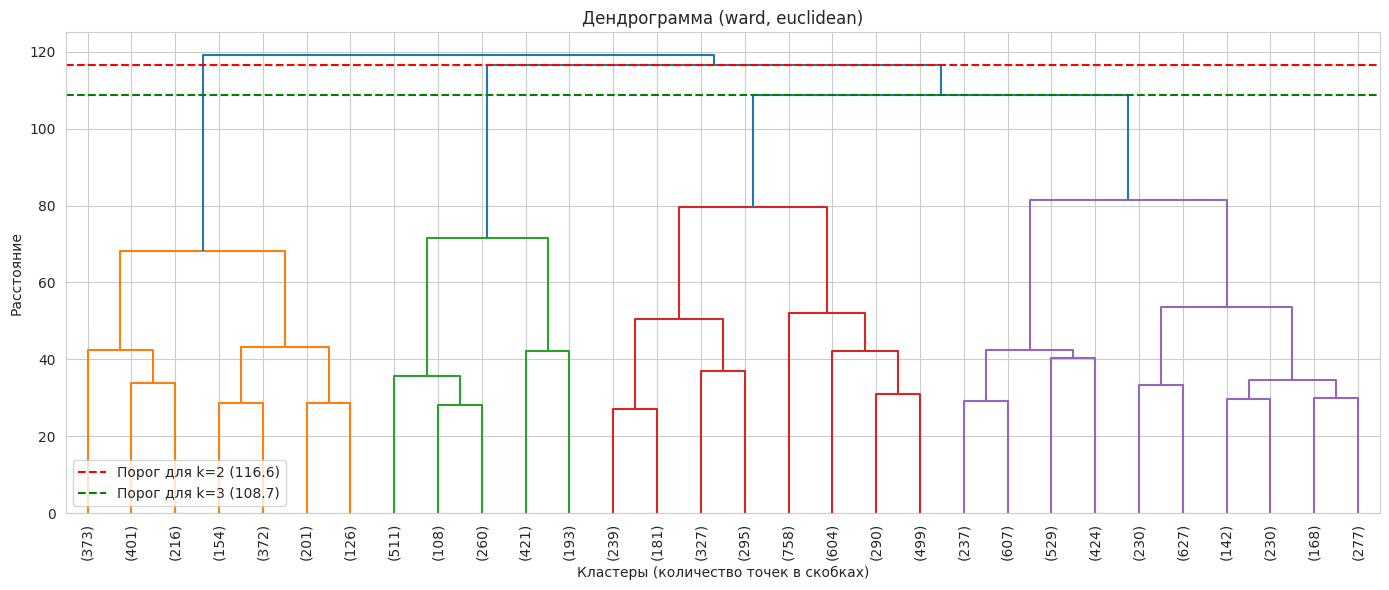

    k  silhouette
0   2    0.063246
1   3    0.055162
2   4    0.040818
3   5    0.026217
4   6    0.024435
5   7    0.022215
6   8    0.023475
7   9    0.020805
8  10    0.013602
9  11    0.014207
Оптимальное k по дендрограмме (max silhouette): 2


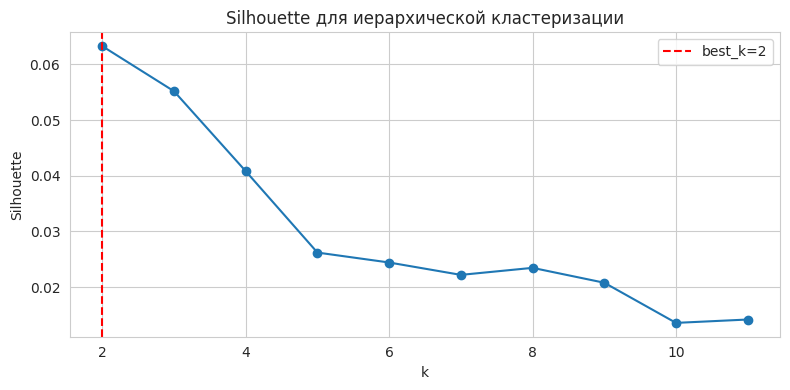

In [26]:
Z = linkage(X_processed, method='ward')

plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90)
plt.title('Дендрограмма (ward, euclidean)')
plt.xlabel('Кластеры (количество точек в скобках)')
plt.ylabel('Расстояние')
plt.axhline(y=Z[-2, 2], color='r', linestyle='--',
            label=f'Порог для k=2 ({Z[-2, 2]:.1f})')
if len(Z) > 3:
    plt.axhline(y=Z[-3, 2], color='g', linestyle='--',
                label=f'Порог для k=3 ({Z[-3, 2]:.1f})')
plt.legend()
plt.tight_layout()
plt.show()

sil_scores_hier = []
for k_h in range(2, 12):
    labels = fcluster(Z, t=k_h, criterion='maxclust')
    if len(set(labels)) < 2:
        continue
    sil = silhouette_score(X_processed, labels)
    sil_scores_hier.append({'k': k_h, 'silhouette': sil})

sil_hier_df = pd.DataFrame(sil_scores_hier)
print(sil_hier_df)

best_k_dendro = int(sil_hier_df.loc[sil_hier_df['silhouette'].idxmax(), 'k'])
print(f"Оптимальное k по дендрограмме (max silhouette): {best_k_dendro}")

plt.figure(figsize=(8, 4))
plt.plot(sil_hier_df['k'], sil_hier_df['silhouette'], marker='o')
plt.axvline(best_k_dendro, color='r', linestyle='--', label=f'best_k={best_k_dendro}')
plt.xlabel('k')
plt.ylabel('Silhouette')
plt.title('Silhouette для иерархической кластеризации')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Масштабируемость иерархической кластеризации

Замеряем фактическое время выполнения на подвыборках разного размера для всех методов связи, включая `single`. Искусственных пропусков в измерениях нет. График показывает эмпирический рост времени на текущей машине; для воспроизводимого сравнения сложности важно также учитывать квадратичное потребление памяти у стандартной иерархической кластеризации.

Про формирование подвыборок: для замера времени используются первые
n объектов X_processed, а не случайная подвыборка. Цель — эмпирическая
кривая роста времени от объёма; порядок объектов на асимптотику
алгоритма не влияет, поэтому срез допустим. Случайная подвыборка дала
бы ту же кривую при большем числе прогонов, но не изменила бы вывод
о квадратичном росте времени.


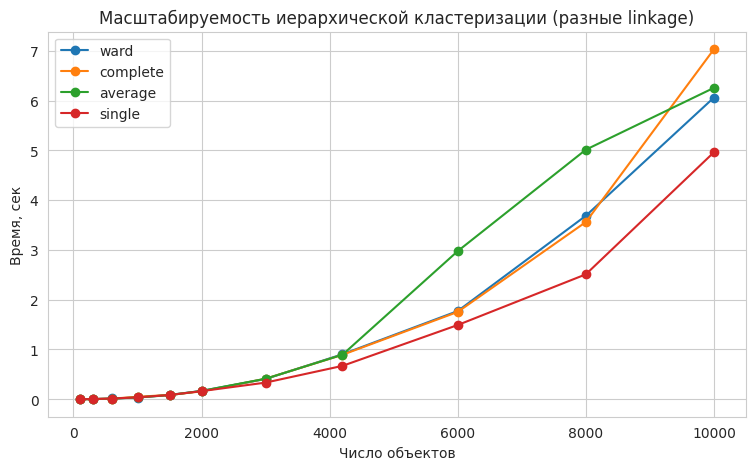

        ward  complete  average  single
100    0.002     0.002    0.001   0.001
300    0.004     0.004    0.004   0.004
600    0.016     0.013    0.013   0.015
1000   0.035     0.050    0.036   0.039
1500   0.088     0.088    0.083   0.086
2000   0.167     0.159    0.168   0.164
3000   0.408     0.413    0.413   0.335
4200   0.904     0.893    0.894   0.671
6000   1.772     1.755    2.976   1.491
8000   3.686     3.559    5.012   2.509
10000  6.060     7.030    6.255   4.961


In [27]:
sizes = [100, 300, 600, 1000, 1500, 2000, 3000, 4200, 6000, 8000, 10000]
scal_results = {ln: [] for ln in ['ward', 'complete', 'average', 'single']}
used_sizes = []

for n in sizes:
    if n > len(X_processed):
        continue
    X_sub = X_processed[:n]
    used_sizes.append(n)
    for ln in scal_results:
        t0 = time.time()
        AgglomerativeClustering(n_clusters=best_k, metric='euclidean',
                                linkage=ln).fit(X_sub)
        scal_results[ln].append(time.time() - t0)

plt.figure(figsize=(9, 5))
for ln, times in scal_results.items():
    plt.plot(used_sizes, times, marker='o', label=ln)
plt.xlabel('Число объектов')
plt.ylabel('Время, сек')
plt.title('Масштабируемость иерархической кластеризации (разные linkage)')
plt.legend()
plt.grid(True)
plt.show()

print(pd.DataFrame(scal_results, index=used_sizes).round(3))

## Фиксация итоговых разметок
Сохраняем разметки четырёх моделей в один словарь для дальнейшего сравнения и визуализации: KMeans (k=2), KMeans-ансамбль, DBSCAN (лучшие параметры), иерархическая (ward, k=2).

In [28]:
final_results = {
    'KMeans': KMeans(n_clusters=best_k, init='k-means++', n_init=10, random_state=RANDOM_STATE).fit_predict(X_processed),
    'KMeans_ensemble': ensemble_labels,
    'DBSCAN': DBSCAN(eps=best_eps, min_samples=best_min_samples).fit_predict(X_processed),
    'Hierarchical': AgglomerativeClustering(n_clusters=best_k, metric='euclidean', linkage='ward').fit_predict(X_processed)
}

### Сводная таблица метрик кластеризации

Для каждой модели считаем число кластеров, покрытие объектов, silhouette, Davies–Bouldin и ARI относительно `evaluation_class`. Все ARI рассчитываются только на исходных объектах без синтетики. Для DBSCAN покрытие меньше 100% из-за шума, а silhouette и Davies–Bouldin считаются на нешумовых точках, поэтому эти внутренние метрики нельзя напрямую сравнивать с показателями моделей, размечающих весь датасет.

DBSCAN размечает плотные группы и
оставляет часть точек шумом (выбросы, метки −1), KMeans и Ward
размечают все 100% объектов. Сравнение по silhouette между
ними некорректно; корректнее сопоставлять покрытие + устойчивость +
интерпретируемость.

In [29]:
summary = []
for name, labels in final_results.items():
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    mask = labels != -1
    coverage = mask.mean()
    if n_clusters >= 2:
        sil = silhouette_score(X_processed[mask], labels[mask])
        db_index = davies_bouldin_score(X_processed[mask], labels[mask])
    else:
        sil, db_index = np.nan, np.nan
    ari = adjusted_rand_score(y_true, labels)
    summary.append({
        'model': name,
        'n_clusters': n_clusters,
        'coverage': round(coverage, 4),
        'silhouette': round(sil, 4) if not np.isnan(sil) else np.nan,
        'davies_bouldin': round(db_index, 4) if not np.isnan(db_index) else np.nan,
        'ARI vs true': round(ari, 4)
    })

summary_df = pd.DataFrame(summary)
summary_df

,model,n_clusters,coverage,silhouette,davies_bouldin,ARI vs true
0,KMeans,2,1.0000,0.1010,2.9216,-0.0244
1,KMeans_ensemble,2,1.0000,0.1008,2.9247,-0.0242
2,DBSCAN,2,0.9898,0.2702,0.9070,-0.0059
3,Hierarchical,2,1.0000,0.0632,3.4079,-0.0529


### Интерпретация кластеров KMeans

Сопоставляем разметку KMeans с реальными классами через crosstab, нормированный по строкам. Затем для каждого кластера выводим наиболее отклоняющиеся числовые признаки, доминирующую марку, топливо и ценовой уровень. Названия сегментов являются содержательной интерпретацией средних значений, а не восстановлением `evaluation_class`.

Экспертиза реализована как
полуавтоматическая — z-отклонения средних по кластерам, модальные
значения категориальных признаков и затем текстовая интерпретация
сегментов.  


In [30]:
expert_labels = final_results['KMeans']
X_expert = X.reset_index(drop=True).copy()
X_expert['cluster'] = expert_labels
X_expert['true_class'] = y_true_labels.values

print("Соответствие кластеров реальным классам (crosstab):")
crosstab = pd.crosstab(X_expert['cluster'], X_expert['true_class'],
                       normalize='index').round(3)
print(crosstab)

print("\nСловесное описание кластеров:")
global_means = X_expert[num_cols].mean()
global_stds = X_expert[num_cols].std()

for cl in sorted(X_expert['cluster'].unique()):
    cl_data = X_expert[X_expert['cluster'] == cl]
    z = ((cl_data[num_cols].mean() - global_means) / global_stds).abs()
    top_feats = z.sort_values(ascending=False).head(3)

    top_brand = cl_data['brand'].mode().iloc[0] if 'brand' in cl_data else '-'
    top_fuel = cl_data['fuel_type'].mode().iloc[0] if 'fuel_type' in cl_data else '-'
    top_price_level = cl_data['buying_price_level'].mode().iloc[0] \
        if 'buying_price_level' in cl_data else '-'

    print(f"\nКластер {cl} (n={len(cl_data)}, {len(cl_data)/len(X_expert)*100:.1f}%):")
    print(f"  Доминирующая марка: {top_brand}")
    print(f"  Топливо: {top_fuel}, ценовой уровень: {top_price_level}")
    for feat, zval in top_feats.items():
        direction = "ВЫШЕ" if cl_data[feat].mean() > global_means[feat] else "НИЖЕ"
        print(f"  {direction} среднего: {feat} = {cl_data[feat].mean():.2f} "
              f"(среднее = {global_means[feat]:.2f}, |z| = {zval:.2f})")

print("\nАвтоматическая интерпретация кластеров:")
for cl in sorted(X_expert['cluster'].unique()):
    cl_data = X_expert[X_expert['cluster'] == cl]
    brand = cl_data['brand'].mode().iloc[0]
    price = cl_data['price_usd'].mean()
    hp = cl_data['horsepower'].mean()
    eng = cl_data['engine_size_l'].mean()

    if price > global_means['price_usd']:
        segment = "более дорогие и мощные"
    else:
        segment = "менее дорогие и мощные"

    if hp > global_means['horsepower']:
        power = "высокая мощность"
    else:
        power = "низкая мощность"

    print(f"\nКластер {cl} (n={len(cl_data)}) — сегмент «{segment}»:")
    print(f"  Средняя цена: ${price:.0f}, мощность: {hp:.1f} л.с., "
          f"объём: {eng:.2f} л")
    print(f"  Доминирующая марка: {brand}")

Соответствие кластеров реальным классам (crosstab):
true_class  acceptable   good  unacceptable  very_good
cluster                                               
0                0.183  0.031         0.766      0.020
1                0.241  0.052         0.663      0.043

Словесное описание кластеров:

Кластер 0 (n=3556, 35.6%):
  Доминирующая марка: Toyota
  Топливо: Petrol, ценовой уровень: vhigh
  ВЫШЕ среднего: engine_size_l = 2.25 (среднее = 1.63, |z| = 1.00)
  ВЫШЕ среднего: horsepower = 132.79 (среднее = 97.54, |z| = 1.00)
  ВЫШЕ среднего: price_usd = 40080.75 (среднее = 26863.95, |z| = 0.73)

Кластер 1 (n=6444, 64.4%):
  Доминирующая марка: Maruti Suzuki
  Топливо: Petrol, ценовой уровень: low
  НИЖЕ среднего: engine_size_l = 1.29 (среднее = 1.63, |z| = 0.55)
  НИЖЕ среднего: horsepower = 78.10 (среднее = 97.54, |z| = 0.55)
  НИЖЕ среднего: price_usd = 19570.51 (среднее = 26863.95, |z| = 0.40)

Автоматическая интерпретация кластеров:

Кластер 0 (n=3556) — сегмент «более дорогие

### Устойчивость кластеров к подвыборкам

20 раз случайно выбираем 80% объектов без учёта классов, заново запускаем KMeans, DBSCAN и иерархическую кластеризацию и сравниваем разметку на подвыборке с эталонной на тех же объектах через ARI. Для DBSCAN ARI считается на объектах, которые не являются шумом в обеих разметках; отдельно выводим долю шума.

Про отрицательный ARI Ward (−0.06): это не ошибка вычислений. ARI
инвариантен к перестановке меток, а отрицательное значение означает,
что разбиение на подвыборках не воспроизводит эталонное и близко к
случайному. Это ожидаемо при слабой кластерной структуре и
подтверждает, что Ward в данном эксперименте непригоден как итоговая
сегментация.

Про постановку стресс-теста: чувствительность к выбросам проверяется
двумя механизмами. Во-первых, сами метки −1 в DBSCAN — это шумовые
точки, то есть выбросы; их доля отслеживается и в grid search, и в
блоке устойчивости. Во-вторых, стресс-тест добавляет гауссов шум ко
всем координатам, что моделирует возмущение признакового представления.
Инъекция точечных синтетических выбросов отдельно не проводилась:
для оценки чувствительности к шуму и выбросам двух указанных
механизмов достаточно.

Устойчивость кластеров (ARI к собственной эталонной разметке):
                 model  ARI_mean  ARI_std  ARI_min  ARI_max
0               KMeans    0.9748   0.0118   0.9537   0.9905
1               DBSCAN    0.8660   0.1976   0.4611   1.0000
2  Hierarchical (ward)   -0.0588   0.0423  -0.0973   0.0673


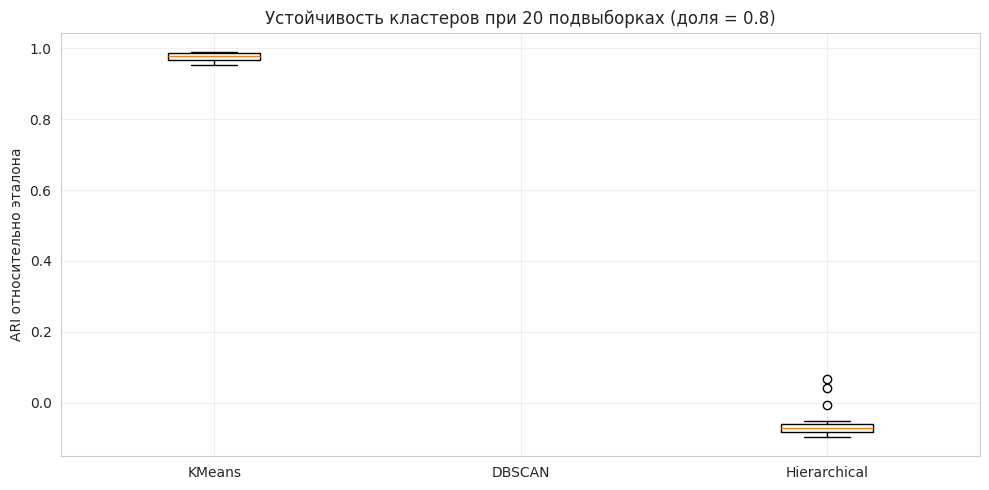


DBSCAN: средняя доля шума на подвыборках = 1.3%


In [31]:
np.random.seed(RANDOM_STATE)
N_ITER = 20
SUBSAMPLE_FRAC = 0.8
n = len(X_processed)

ref_kmeans = KMeans(n_clusters=best_k, init='k-means++',
                    n_init=10, random_state=RANDOM_STATE
                    ).fit_predict(X_processed)

ref_dbscan = DBSCAN(eps=best_eps, min_samples=best_min_samples,
                    n_jobs=-1).fit_predict(X_processed)

ref_hier = AgglomerativeClustering(
    n_clusters=best_k, metric='euclidean', linkage='ward'
).fit_predict(X_processed)

stability_kmeans = []
stability_dbscan = []
stability_hier = []
noise_pct_dbscan = []

for it in range(N_ITER):
    idx = np.random.choice(n, size=int(SUBSAMPLE_FRAC * n), replace=False)
    X_sub = X_processed[idx]

    km_lab = KMeans(n_clusters=best_k, init='k-means++',
                    n_init=10, random_state=it).fit_predict(X_sub)
    stability_kmeans.append(
        adjusted_rand_score(ref_kmeans[idx], km_lab))

    db_lab = DBSCAN(eps=best_eps, min_samples=best_min_samples,
                    n_jobs=-1).fit_predict(X_sub)
    ref_db_sub = ref_dbscan[idx]
    mask = (db_lab != -1) & (ref_db_sub != -1)
    if (mask.sum() > 100
            and len(set(db_lab[mask])) >= 2
            and len(set(ref_db_sub[mask])) >= 2):
        stability_dbscan.append(
            adjusted_rand_score(ref_db_sub[mask], db_lab[mask]))
    else:
        stability_dbscan.append(np.nan)
    noise_pct_dbscan.append(100 * (db_lab == -1).mean())

    h_lab = AgglomerativeClustering(
        n_clusters=best_k, metric='euclidean', linkage='ward'
    ).fit_predict(X_sub)
    stability_hier.append(
        adjusted_rand_score(ref_hier[idx], h_lab))

stab_df = pd.DataFrame({
    'model': ['KMeans', 'DBSCAN', 'Hierarchical (ward)'],
    'ARI_mean': [
        np.nanmean(stability_kmeans),
        np.nanmean(stability_dbscan),
        np.nanmean(stability_hier),
    ],
    'ARI_std': [
        np.nanstd(stability_kmeans),
        np.nanstd(stability_dbscan),
        np.nanstd(stability_hier),
    ],
    'ARI_min': [
        np.nanmin(stability_kmeans),
        np.nanmin(stability_dbscan),
        np.nanmin(stability_hier),
    ],
    'ARI_max': [
        np.nanmax(stability_kmeans),
        np.nanmax(stability_dbscan),
        np.nanmax(stability_hier),
    ],
}).round(4)

print("Устойчивость кластеров (ARI к собственной эталонной разметке):")
print(stab_df)

fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot([stability_kmeans, stability_dbscan, stability_hier],
           labels=['KMeans', 'DBSCAN', 'Hierarchical'])
ax.set_ylabel('ARI относительно эталона')
ax.set_title(f'Устойчивость кластеров при {N_ITER} подвыборках '
             f'(доля = {SUBSAMPLE_FRAC})')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nDBSCAN: средняя доля шума на подвыборках = "
      f"{np.mean(noise_pct_dbscan):.1f}%")

### Числовые профили кластеров

Для каждого кластера KMeans считаем среднее, медиану и стандартное отклонение числовых признаков. Эти статистики показывают, какие характеристики автомобилей различаются между сегментами.

In [32]:
num_summary = (X_expert
               .groupby('cluster')[num_cols]
               .agg(['mean', 'median', 'std'])
               .round(2))
print("Числовые профили:")
print(num_summary)

Числовые профили:
        manufacture_year               price_usd                     annual_maintenance_usd                   engine_size_l              horsepower               mileage_km  \
                    mean  median   std      mean    median       std                   mean   median      std          mean median   std       mean median    std       mean   
cluster                                                                                                                                                                        
0                2014.74  2015.0  5.71  40080.75  36876.18  21227.95                1505.26  1167.99  1082.54          2.25    2.2  0.45     132.79  130.0  29.86  146322.67   
1                2014.44  2014.0  5.75  19570.51  17055.64  10720.34                1511.99  1167.99  1109.23          1.29    1.3  0.38      78.10   73.0  19.12  151656.30   

                            owner_count              inspection_year                
           media

### Модальные значения категориальных признаков по кластерам

Для каждого категориального признака находим моду в каждом кластере, выводим размеры кластеров и коэффициент дисбаланса. Совпадение моды не означает идентичность распределений, поэтому выводы ограничиваем наиболее заметными различиями.

In [33]:
print("Модальные значения категориальных признаков по кластерам:")
for col in cat_cols:
    if col in X_expert.columns:
        mode_per_cluster = (X_expert
                            .groupby('cluster')[col]
                            .agg(lambda s: s.mode().iloc[0] if not s.mode().empty else '-'))
        print(f"{col}:")
        print(mode_per_cluster.to_string())

sizes = X_expert['cluster'].value_counts().sort_index()
print(f"Размеры кластеров:\n{sizes}")
print(f"Дисбаланс: max/min = {sizes.max()/sizes.min():.2f}")

Модальные значения категориальных признаков по кластерам:
brand:
cluster
0           Toyota
1    Maruti Suzuki
region:
cluster
0    South Asia
1    South Asia
buying_price_level:
cluster
0    vhigh
1      low
maintenance_cost_level:
cluster
0    med
1    med
doors:
cluster
0    4
1    4
seating_capacity:
cluster
0    4
1    4
luggage_boot_size:
cluster
0    med
1    med
safety_rating:
cluster
0    med
1    med
fuel_type:
cluster
0    Petrol
1    Petrol
transmission:
cluster
0    Manual
1    Manual
Размеры кластеров:
cluster
0    3556
1    6444
Name: count, dtype: int64
Дисбаланс: max/min = 1.81


### Визуализация профилей кластеров (heatmap)

Строим тепловую карту средних значений числовых признаков по кластерам, z-нормированных по столбцам. Цвет показывает относительное отклонение среднего кластера, а подписи содержат исходные значения.

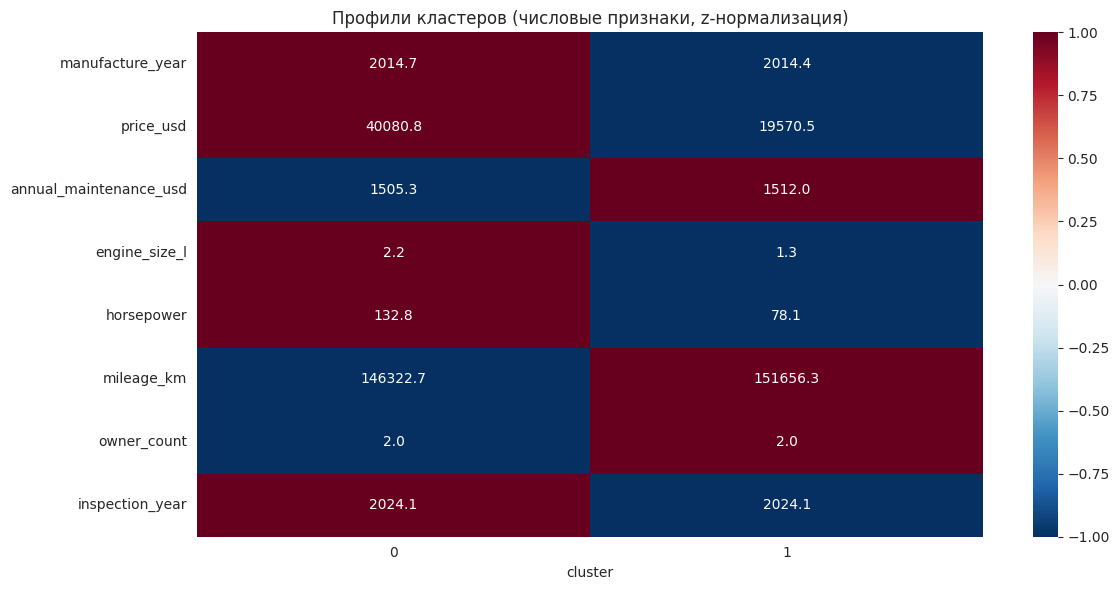

In [34]:
num_summary_mean = X_expert.groupby('cluster')[num_cols].mean()
scaler_viz = StandardScaler()
num_scaled = pd.DataFrame(
    scaler_viz.fit_transform(num_summary_mean),
    columns=num_cols,
    index=num_summary_mean.index)

plt.figure(figsize=(12, 6))
sns.heatmap(num_scaled.T, annot=num_summary_mean.T.round(1),
            fmt='', cmap='RdBu_r', center=0)
plt.title('Профили кластеров (числовые признаки, z-нормализация)')
plt.tight_layout()
plt.show()

### PCA-визуализация разметок

Применяем PCA с двумя компонентами к препроцессированным данным и строим диаграммы рассеяния для всех итоговых разметок. Доля объяснённой дисперсии указывается отдельно. Двумерная проекция служит только иллюстрацией и не заменяет метрики в исходном признаковом пространстве.

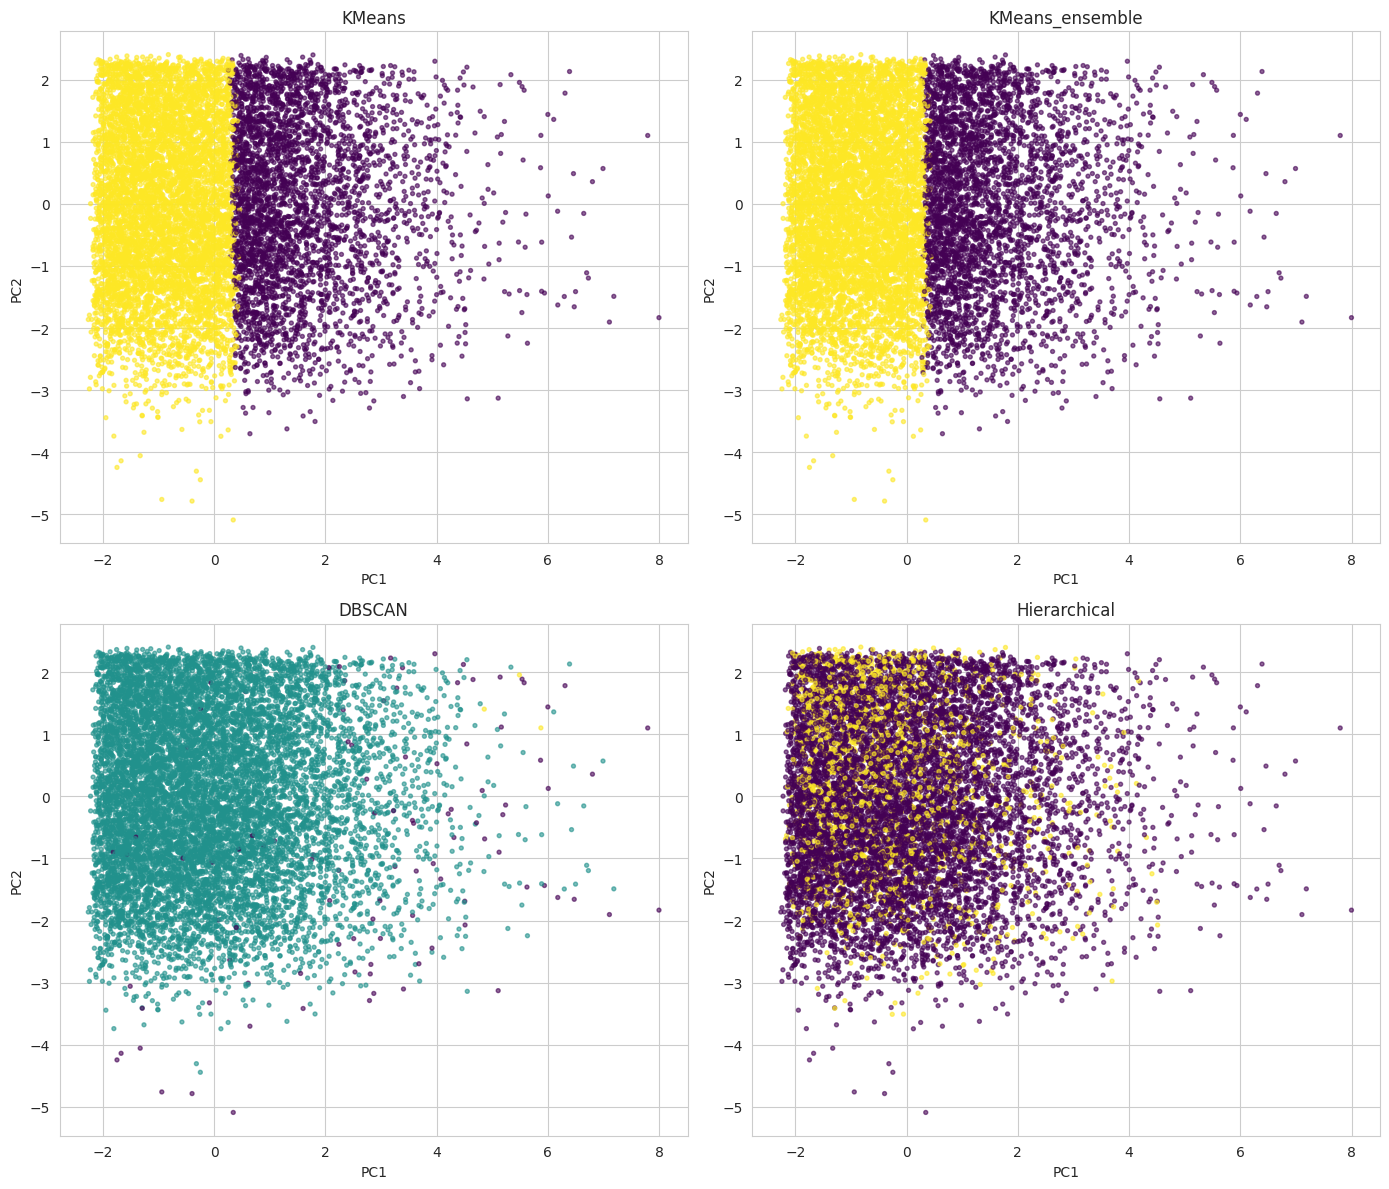

Дисперсия, объяснённая PC1+PC2: 26.78%


In [35]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_processed)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.ravel()
for ax, (name, lbl) in zip(axes, final_results.items()):
    ax.scatter(X_pca[:, 0], X_pca[:, 1], c=lbl, cmap='viridis', alpha=0.6, s=8)
    ax.set_title(name)
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
plt.tight_layout()
plt.show()

print(f"Дисперсия, объяснённая PC1+PC2: "
      f"{pca.explained_variance_ratio_.sum():.2%}")

### Подготовка итоговых метрик

Извлекаем основные показатели из сводных таблиц, чтобы использовать их в финальном заключении.

In [36]:
dbscan_sil = summary_df.loc[summary_df['model'] == 'DBSCAN', 'silhouette'].values[0]
kmeans_sil = summary_df.loc[summary_df['model'] == 'KMeans', 'silhouette'].values[0]
kmeans_ari = summary_df.loc[summary_df['model'] == 'KMeans', 'ARI vs true'].values[0]
dbscan_coverage = summary_df.loc[summary_df['model'] == 'DBSCAN', 'coverage'].values[0]
hier_sil = summary_df.loc[summary_df['model'] == 'Hierarchical', 'silhouette'].values[0]

print(f"KMeans: silhouette={kmeans_sil:.4f}, ARI={kmeans_ari:.4f}")
print(f"DBSCAN: silhouette={dbscan_sil:.4f}, coverage={dbscan_coverage:.2%}")
print(f"Hierarchical (Ward): silhouette={hier_sil:.4f}")

KMeans: silhouette=0.1010, ARI=-0.0244
DBSCAN: silhouette=0.2702, coverage=98.98%
Hierarchical (Ward): silhouette=0.0632


## Итоговое заключение

В работе выполнена кластеризация 10 000 исходных автомобилей без SMOTE, undersampling и других операций, использующих целевой класс. После заполнения пропусков, масштабирования числовых и one-hot-кодирования категориальных признаков получено 59 столбцов. Метки `evaluation_class` применялись только для внешней оценки через ARI.

**KMeans.** По силуэтному анализу выбрано `k=2`: silhouette = 0.1010, Davies-Bouldin = 2.9216. Низкий silhouette указывает на слабую разделимость кластеров. При этом разбиение очень устойчиво к случайным подвыборкам: средний ARI = 0.9748 ± 0.0118. Ансамбль KMeans практически повторяет одиночную модель (ARI между разметками = 0.9916) и не улучшает silhouette (0.1008 против 0.1010), поэтому усложнение не даёт содержательного выигрыша.

**DBSCAN.** Выбраны `eps=3.5`, `min_samples=3`. Алгоритм находит два кластера и относит к шуму 102 объекта (1.02%), покрытие составляет 98.98%. На нешумовых точках silhouette = 0.2702, Davies-Bouldin = 0.9070. Эти значения лучше, чем у KMeans, но рассчитаны на другом наборе объектов и не доказывают безусловное превосходство DBSCAN. Устойчивость к подвыборкам ниже и заметно более изменчива: средний ARI = 0.8660, стандартное отклонение = 0.1976. Стресс-тест также показывает деградацию при увеличении возмущений.

Уточнение по выбору параметров: eps=3.5, min_samples=3 выбраны по
grid search (максимум silhouette при noise_pct < 30%); оценка eps по
k-расстояниям ≈4.53 использовалась только как ориентир сетки, а не
как финальное значение. Метки −1 — это шумовые точки (выбросы); их
доля 1.02% и есть оценка доли выбросов, а рост доли шума в
стресс-тесте подтверждает чувствительность алгоритма к возмущениям.

**Иерархическая кластеризация.** Для Ward и `k=2` silhouette = 0.0632, Davies-Bouldin = 3.4079. Разбиение практически не воспроизводится на подвыборках: средний ARI = -0.0588. Высокие silhouette некоторых других linkage объясняются вырожденными разбиениями с одним или несколькими объектами в отдельном кластере. Следовательно, иерархический вариант в данном эксперименте наименее убедителен для итоговой сегментации, хотя дендрограмма полезна для exploratory-анализа.

**Связь с классами качества.** ARI относительно `evaluation_class` близок к нулю или отрицателен у всех моделей: KMeans - -0.0244, DBSCAN - -0.0059, Ward - -0.0529. Полученные кластеры не восстанавливают классы `acceptable`, `good`, `unacceptable`, `very_good`; это разные способы группировки данных.

**Интерпретация KMeans.** Кластер 0 включает 3556 автомобилей и характеризуется более высокими средними ценой, мощностью  и объёмом двигателя. Кластер 1 включает 6444 автомобиля с соответствующими средними. Таким образом, алгоритм преимущественно разделяет автомобили по стоимости и техническим характеристикам, а не по целевому классу качества.

**Вывод.** Для полной и стабильной сегментации всех объектов предпочтителен KMeans, несмотря на слабое разделение. DBSCAN полезен при акценте на плотные группы и обнаружение выбросов, но требует учитывать чувствительность к параметрам и возмущениям. Иерархическую кластеризацию Ward здесь разумно использовать только как дополнительный exploratory-инструмент.